<a href="https://colab.research.google.com/github/curtismutuma-rgb/AI-for-Science-and-Engineering-Short-Course/blob/main/ChestMNIST_Descriptive_Statistics_Correlation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ChestMNIST: Descriptive Statistics and Correlation

This notebook continues the medical disease-identification project using the ChestMNIST dataset from the previous assignment. It summarizes two image-derived numerical features and one disease-label variable from the training split. The code downloads ChestMNIST through the official MedMNIST Python package if it is not already available in the Colab runtime.


## Selected numerical variables

I will analyze three numerical variables:

1. **Mean pixel intensity:** the average grayscale pixel value in each chest X-ray.
2. **Pixel-intensity standard deviation:** the spread of pixel values within each image, used here as a simple measure of image contrast.
3. **Pneumonia label:** a binary target from ChestMNIST (1 means the dataset reports the pneumonia label; 0 means it does not). Because ChestMNIST labels are report-mined, a 0 should not be treated as a confirmed clinical negative.

For covariance, correlation, and the plot, I will compare mean pixel intensity (input) with the pneumonia label (output). These simple image summaries are for a statistics exercise; they are not a substitute for using the full image in a validated medical model.


In [1]:
# Install the official dataset package in the Colab runtime.
!pip -q install medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 8.7 MB/s eta 0:00:00


In [2]:
# Import the libraries and load the training split of ChestMNIST.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from medmnist import ChestMNIST, INFO

train_data = ChestMNIST(split="train", download=True)
label_map = INFO["chestmnist"]["label"]
label_names = [label_map[str(i)] for i in range(len(label_map))]
pneumonia_index = label_names.index("pneumonia")

# Compute brightness and contrast features from the pixels of each image.
image_pixels = np.asarray(train_data.imgs).reshape(len(train_data), -1)
mean_pixel_intensity = image_pixels.mean(axis=1)
pixel_intensity_std = image_pixels.std(axis=1)

# Extract the pneumonia indicator from the dataset's multi-label targets.
label_matrix = np.asarray(train_data.labels).reshape(len(train_data), -1).astype(int)
pneumonia_label = label_matrix[:, pneumonia_index]

# Put the three numerical variables into a table and display a few examples.
analysis_df = pd.DataFrame({
    "mean_pixel_intensity": mean_pixel_intensity,
    "pixel_intensity_std": pixel_intensity_std,
    "pneumonia_label": pneumonia_label,
})
print(f"Training images analyzed: {len(analysis_df):,}")
print(f"Pneumonia label index: {pneumonia_index}")
display(analysis_df.head())

100%|██████████| 82.8M/82.8M [01:55<00:00, 715kB/s]


Training images analyzed: 78,468
Pneumonia label index: 6


,mean_pixel_intensity,pixel_intensity_std,pneumonia_label
0,136.696429,64.064677,0
1,107.508929,70.868680,0
2,120.358418,54.761383,0
3,132.668367,62.913345,0
4,126.757653,67.160484,0


In [3]:
# Calculate mean, median, range, sample variance, and sample standard deviation.
variables = [
    "mean_pixel_intensity",
    "pixel_intensity_std",
    "pneumonia_label",
]
statistics = pd.DataFrame({
    "mean": analysis_df[variables].mean(),
    "median": analysis_df[variables].median(),
    "range": analysis_df[variables].max() - analysis_df[variables].min(),
    "variance": analysis_df[variables].var(ddof=1),
    "standard_deviation": analysis_df[variables].std(ddof=1),
})
display(statistics.round(4))
print("Variance and standard deviation above use the sample formula (ddof=1).")

,mean,median,range,variance,standard_deviation
mean_pixel_intensity,125.8705,120.7889,203.648,514.4504,22.6815
pixel_intensity_std,55.2932,56.6550,89.716,111.7158,10.5696
pneumonia_label,0.0125,0.0000,1.000,0.0123,0.1109


Variance and standard deviation above use the sample formula (ddof=1).


In [4]:
# Measure covariance and Pearson correlation between image brightness and the pneumonia label.
input_variable = "mean_pixel_intensity"
output_variable = "pneumonia_label"
covariance = analysis_df[input_variable].cov(analysis_df[output_variable])
correlation = analysis_df[input_variable].corr(analysis_df[output_variable])
print(f"Covariance: {covariance:.4f}")
print(f"Pearson correlation: {correlation:.4f}")

Covariance: -0.0508
Pearson correlation: -0.0202


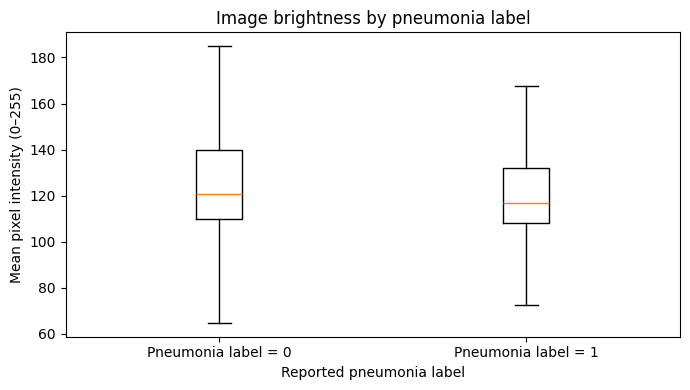

In [5]:
# Compare the distribution of mean pixel intensity for the two pneumonia-label groups.
no_label = analysis_df.loc[analysis_df["pneumonia_label"] == 0, "mean_pixel_intensity"]
positive_label = analysis_df.loc[analysis_df["pneumonia_label"] == 1, "mean_pixel_intensity"]
plt.figure(figsize=(7, 4))
plt.boxplot([no_label, positive_label], showfliers=False)
plt.xticks([1, 2], ["Pneumonia label = 0", "Pneumonia label = 1"])
plt.ylabel("Mean pixel intensity (0–255)")
plt.xlabel("Reported pneumonia label")
plt.title("Image brightness by pneumonia label")
plt.tight_layout()
plt.show()

## Short interpretation

The mean and median describe typical image brightness and contrast, while the range shows the full observed spread. Variance and standard deviation describe how much the values vary across training images; standard deviation is in the original variable's units. For the binary pneumonia label, its mean is the fraction of training examples carrying that label in this dataset, not a population disease rate.

The printed correlation is between mean pixel intensity and the 0/1 pneumonia label. A positive value means higher brightness tends to occur with the positive label; a negative value means it tends to occur with the zero label; a value near zero indicates little linear association. Since one variable is binary, this Pearson correlation is also called a point-biserial correlation. Use the computed value above to describe the direction and strength.

Correlation does **not** prove that brightness causes pneumonia or that pneumonia causes a particular brightness. Image exposure, equipment, preprocessing, patient mix, and other factors could influence the association.


## Input → model → output

For a simple mathematical illustration, use mean pixel intensity as the input and the reported pneumonia label as the output:

`xᵢ = mean_pixel_intensityᵢ  →  fθ(xᵢ) = σ(β₀ + β₁xᵢ)  →  ŷᵢ = 1 if fθ(xᵢ) ≥ 0.5, otherwise 0`

Here, `fθ` is a simple logistic model and `σ` is the sigmoid function. This one-feature expression only illustrates the input–model–output idea; a medically meaningful system would need to analyze the full image, be trained and carefully evaluated, and support—not replace—a clinician.

**Dataset source:** [MedMNIST ChestMNIST](https://medmnist.com/) (official data record: [Zenodo](https://doi.org/10.5281/zenodo.10519652)). Run the code cells in Google Colab to download the dataset and generate the statistics and plot.